In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [38]:
#### INPUT PATH
INPUT_FOLDER = 'tris\\force_dist_v4'
K15_path = os.path.join(INPUT_FOLDER, 'K_015\\obs.dat')
K25_path = os.path.join(INPUT_FOLDER, 'K_025\\obs.dat')

In [39]:
#### LOAD DATA INTO DATAFRAMES
K15_df = pd.read_csv(K15_path, 
                     delim_whitespace=True, 
                     header=None,
                     names=['step','dist','force_mag'])
K25_df = pd.read_csv(K25_path, 
                     delim_whitespace=True, 
                     header=None,
                     names=['step','dist','force_mag'])

C:\Users\Tristan\AppData\Local\Temp\ipykernel_17964\2749011975.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K15_df = pd.read_csv(K15_path,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_17964\2749011975.py:6: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  K25_df = pd.read_csv(K25_path,


In [46]:
#### FILTER DATA
from functions import *

WINDOW_SIZE = 1  # Adjust to control smoothing
K15_df_filtered = moving_average_filter(K15_df, 
                                         window_size=WINDOW_SIZE, 
                                         epoch_col='step', 
                                         filter_cols='force_mag')
K25_df_filtered = moving_average_filter(K25_df, 
                                         window_size=WINDOW_SIZE, 
                                         epoch_col='step', 
                                         filter_cols='force_mag')

Text(0, 0.5, 'Force Magnitude (oxDNA units)')

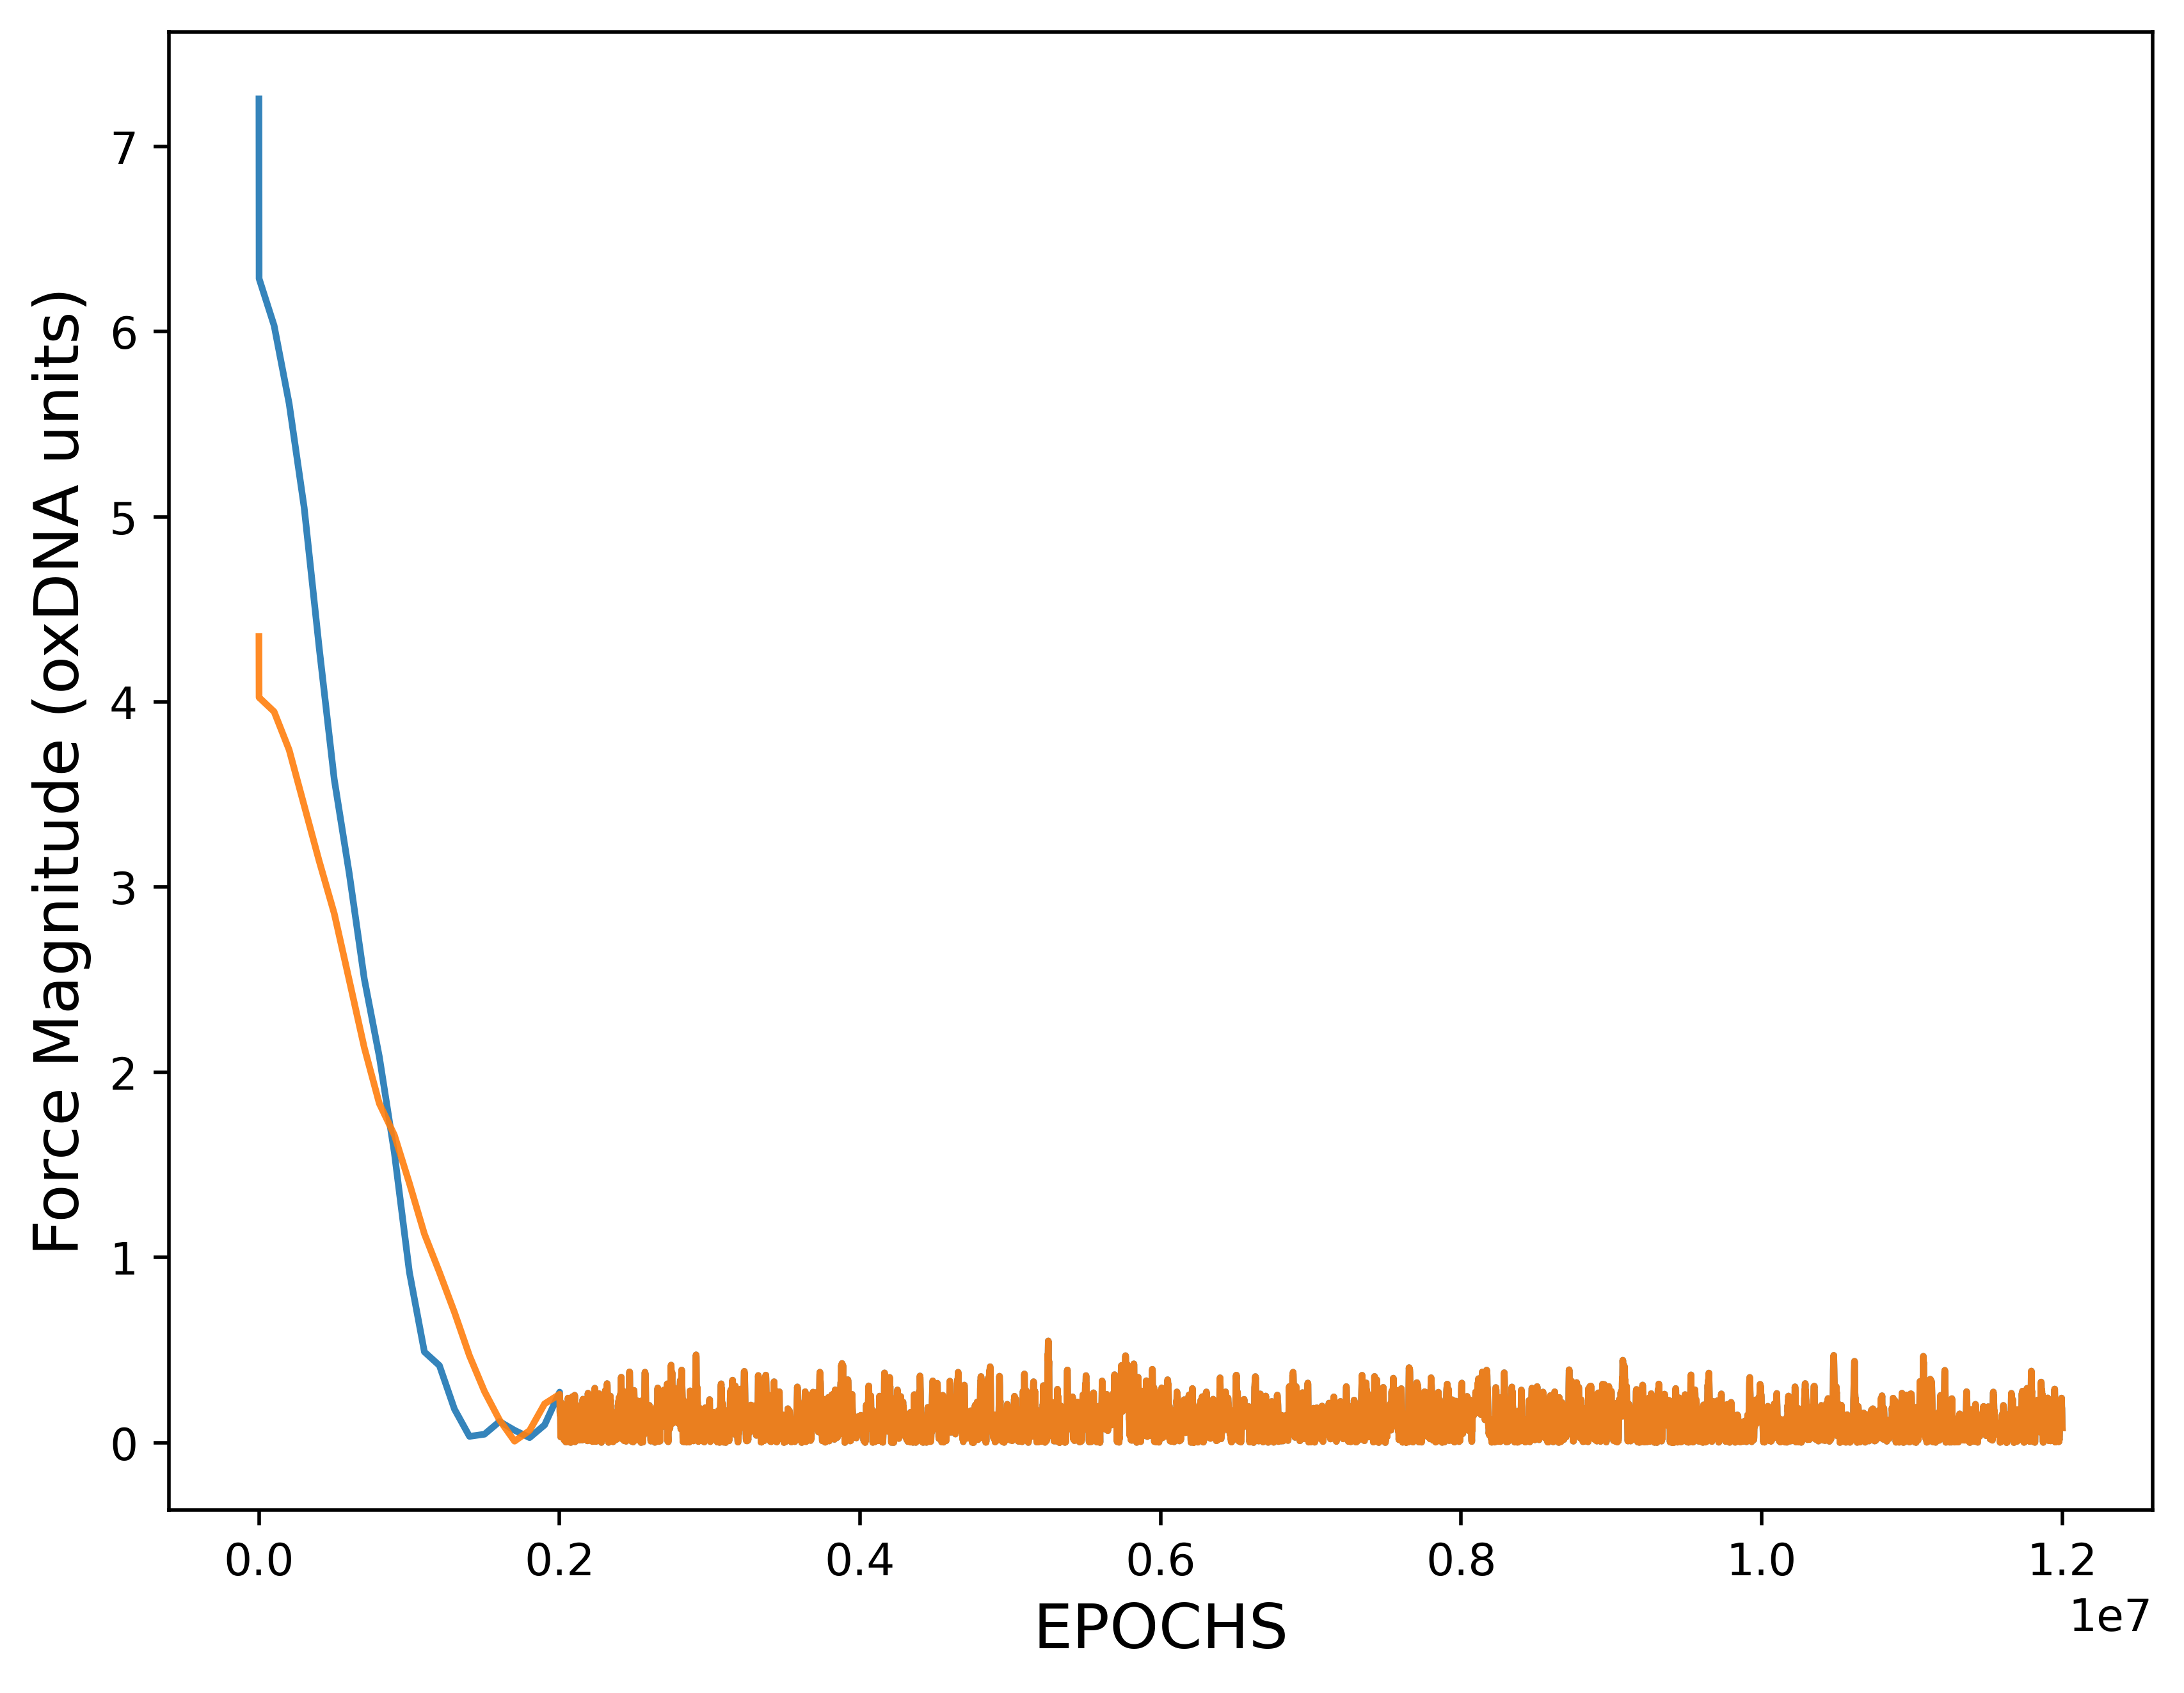

In [ ]:
fig, ax = plt.subplots(figsize=(8,6), dpi=500)
ax.plot(K25_df_filtered['step'], 
        K25_df_filtered['force_mag_filtered'], 
        alpha=0.9, 
        linewidth=1.5,
        label='K=0.25, r0=25')
ax.plot(K15_df_filtered['step'], 
        K15_df_filtered['force_mag_filtered'], 
        alpha=0.9, 
        linewidth=1.5,
        label='K=0.15, r0=15')
ax.set_xlabel('EPOCHS', fontsize=14)
ax.set_ylabel('Force Magnitude (oxDNA units)', fontsize=14)
ax.legend(fontsize=12)

In [42]:
#### APPLY CUTOFF
CUTOFF = 0.2e7  # 2,000,000 steps
K15_df_filtered = K15_df_filtered[K15_df_filtered['step'] >= CUTOFF].reset_index(drop=True)
K25_df_filtered = K25_df_filtered[K25_df_filtered['step'] >= CUTOFF].reset_index(drop=True)

Text(0, 0.5, 'Force Magnitude (oxDNA units)')

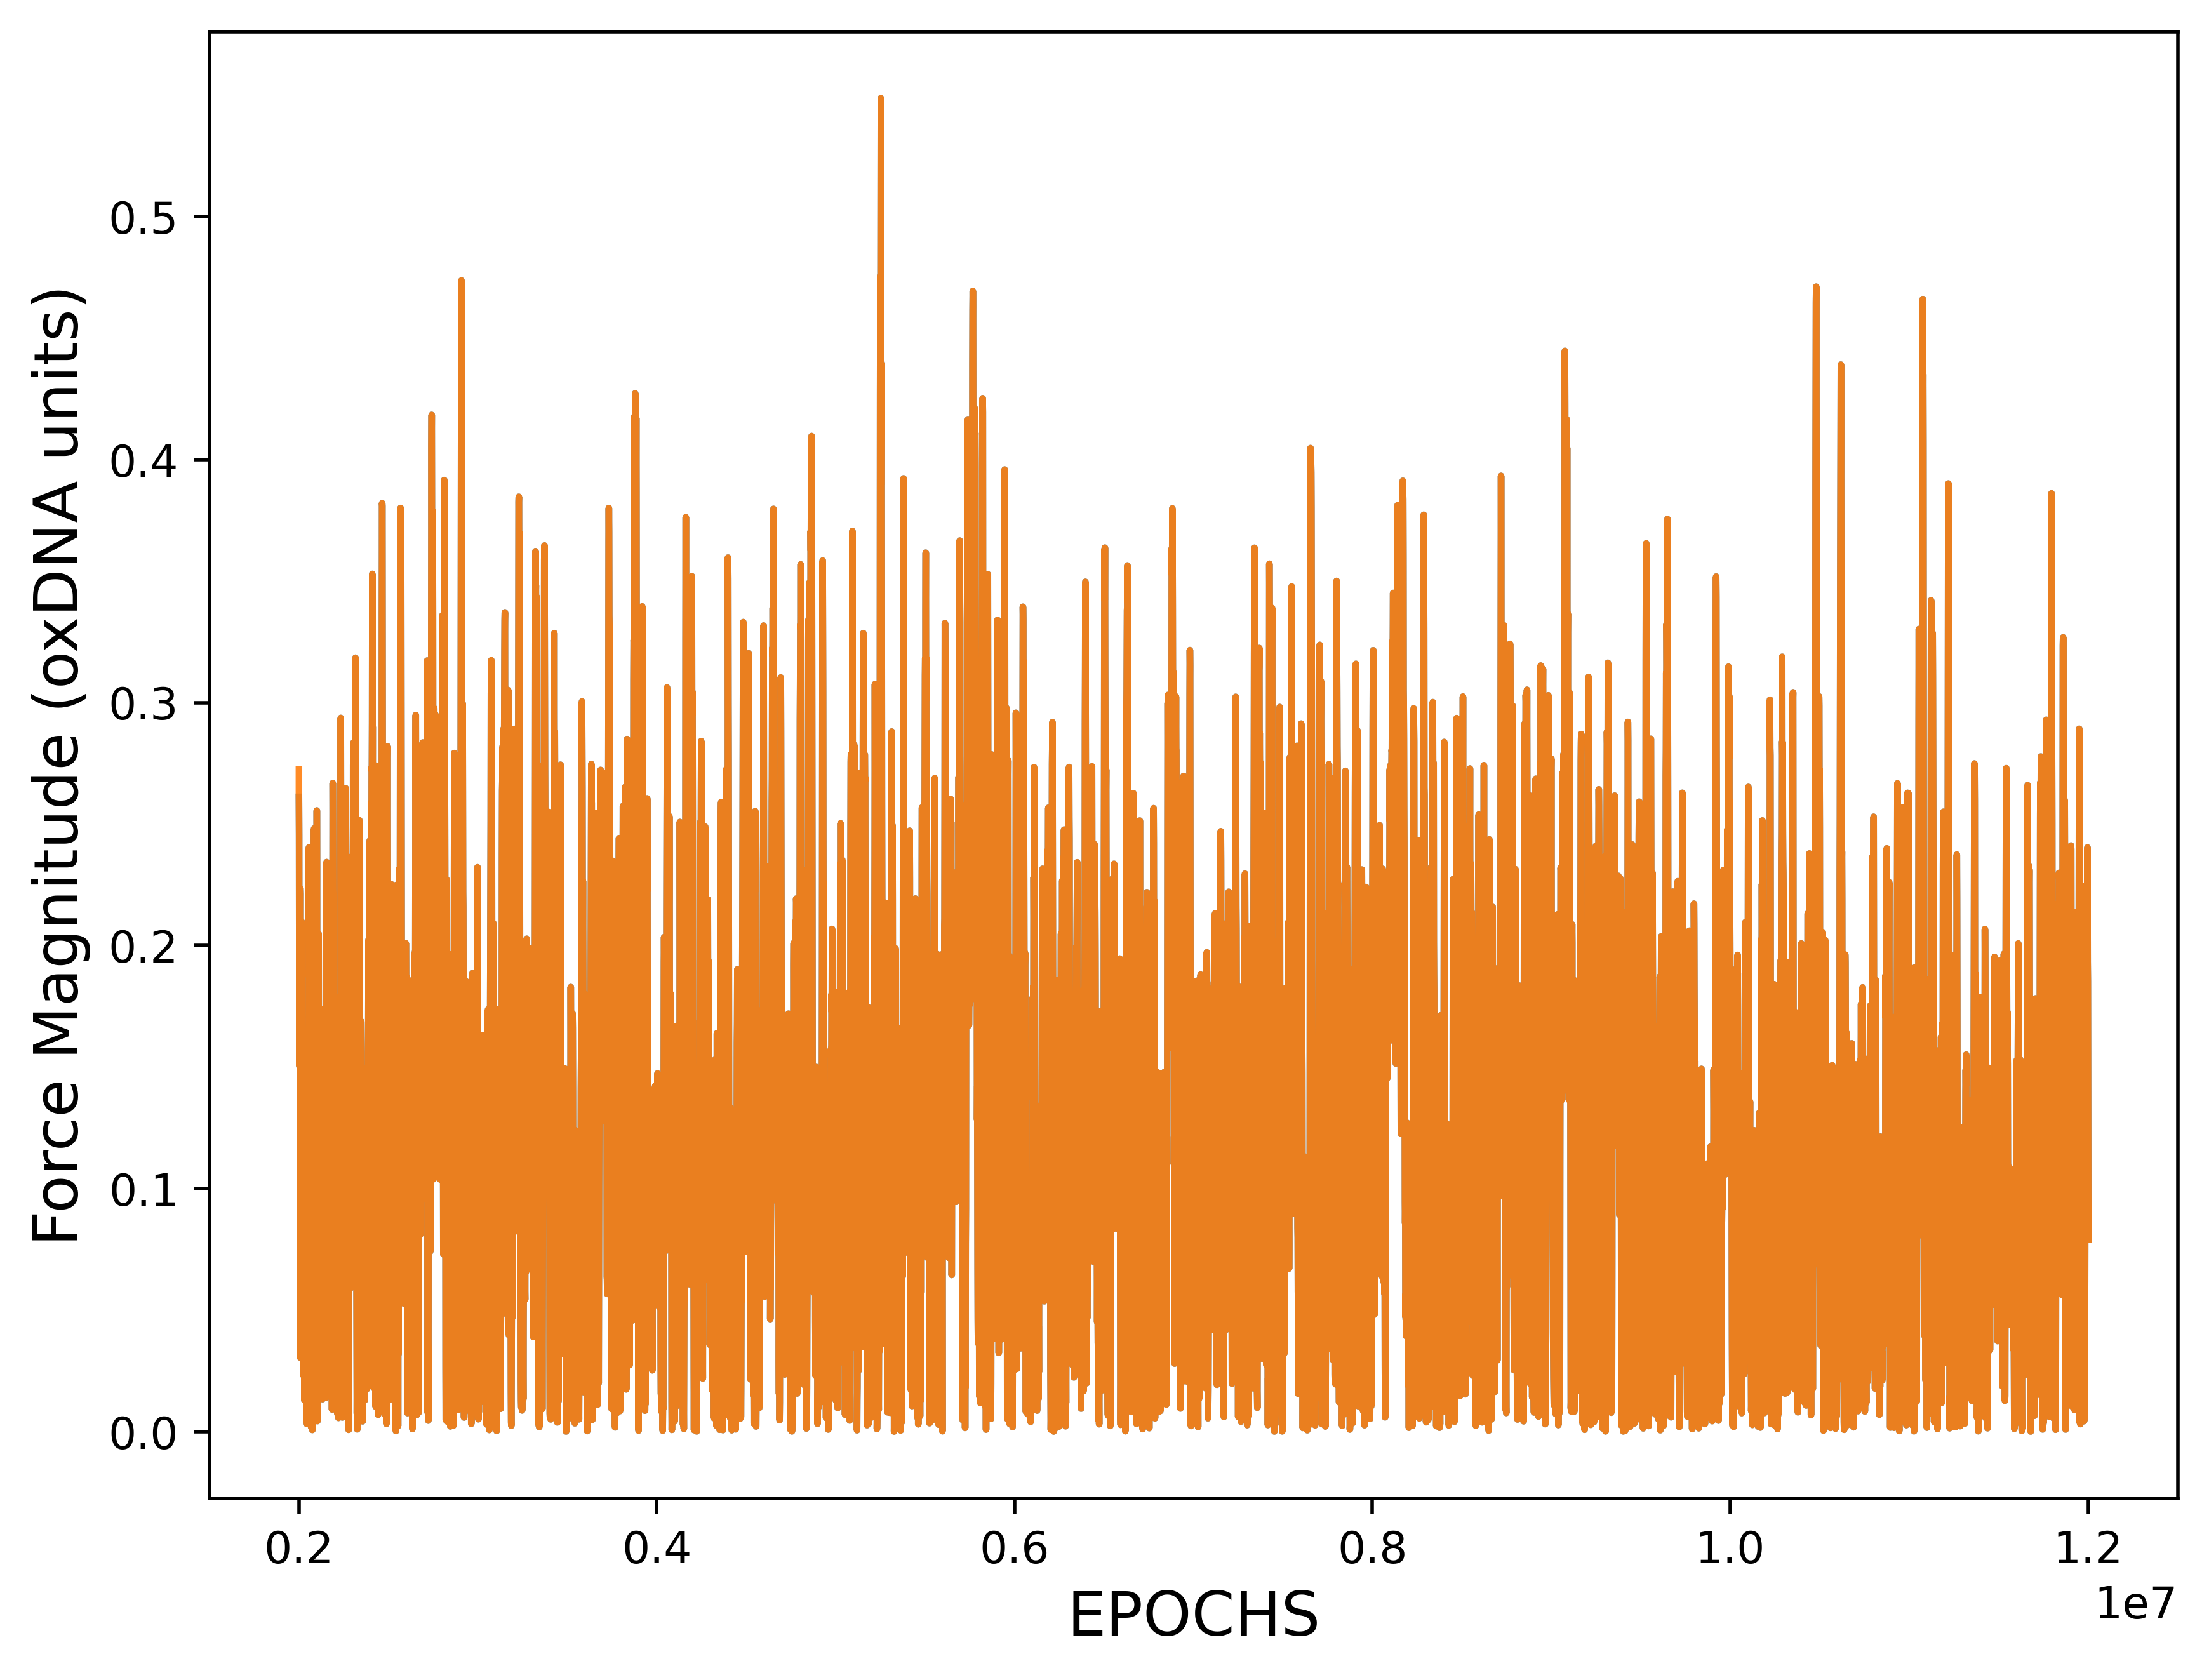

In [43]:
fig, ax = plt.subplots(figsize=(8,6), dpi=500)
ax.plot(K15_df_filtered['step'], K15_df_filtered['force_mag_filtered'], alpha=0.9, linewidth=1.5)
ax.plot(K25_df_filtered['step'], K25_df_filtered['force_mag_filtered'], alpha=0.9, linewidth=1.5)
ax.set_xlabel('EPOCHS', fontsize=14)
ax.set_ylabel('Force Magnitude (oxDNA units)', fontsize=14)

In [44]:
print(np.mean(K15_df_filtered['force_mag_filtered']),
      np.std(K15_df_filtered['force_mag_filtered']))
print(np.mean(K25_df_filtered['force_mag_filtered']),
      np.std(K25_df_filtered['force_mag_filtered']))

0.12760850829358128 0.08812096468635684
0.1276096306345231 0.08812273770314732
